# 03 · Numerical parity, op by op

Text generated by the Relax artifact is close to HF's but not bit-identical. This notebook finds out
where the differences come from. It compiles **one piece of the model at a time** with the
unmodified production pipeline, feeds the real layer-0 weights and real activations through both
implementations, and measures the gap. It then measures how that gap grows across 28 layers and how
much it changes the decoding decisions.

**Needs:** CUDA, the checkpoint, and `artifacts/fast_dllm_relax_bf16` (last section). Each probe
compiles in seconds; the whole notebook runs in a few minutes. Peak GPU memory is about 8 GB (both
models loaded).

How a probe works:
- `make_probe` (in `_helpers.py`) wraps a single submodule as a function named `forward_hidden`.
- The production pipeline only offloads GEMMs to cuBLAS inside its named hot functions, and
  `FuseOpsByPattern` looks each of those names up, so the probe also defines the other names as
  identity stubs.
- With that, the probe gets exactly the kernels the real artifact gets.

In [1]:
from _helpers import *
bootstrap()

repo root: fast-dllm-relax/  (cwd set)  tvm 0.24.dev0  torch 2.10.0+cu128


PosixPath('<repo>')

In [2]:
import numpy as np
import torch
import tvm
from tvm import relax
from fast_dllm_relax.export_utils import make_relax_config
from fast_dllm_relax.model.cuda import (FastDLLMRMSNorm, FastDLLMRelaxMLP, FastDLLMRelaxAttention,
                                         FastDLLMRelaxDecoderLayer, build_prefix_block_attention_bias)

tok, hf = load_hf()
cfg = make_relax_config(hf.config)
DT = "bfloat16"
dev = tvm.cuda(0)
target = tvm.target.Target.from_device(dev)
pipeline = relax.get_pipeline("opt_fast_dllm_llm_cublas", verbose=False)

def compile_probe(kind, inner):
    probe, spec = make_probe(kind, inner, dtype=DT, hidden_size=cfg.hidden_size, num_heads=cfg.num_attention_heads)
    mod, named = probe.export_tvm(spec=spec)
    ex = tvm.compile(mod, target, relax_pipeline=pipeline)
    return relax.VirtualMachine(ex, dev), named

def tvm_in(t):
    return tvm.runtime.from_dlpack(t.contiguous())

PROMPT = 'Natalia sold clips to 48 of her friends in April, and then she sold half as many clips in May. How many clips did Natalia sell altogether in April and May? Explain each step of your reasoning carefully, then give the final answer on its own line.'
L = 64
ids = torch.tensor([chat_ids(tok, PROMPT)[:L]], device="cuda")
assert ids.shape[1] == L
with torch.no_grad():
    x = hf.model.embed_tokens(ids)                                  # real activations, [1, 64, 1536] bf16
pos = torch.arange(L, device="cuda")[None]
mask = hf.model.eval_mask(L, 32, 0).to("cuda")                      # HF: bool block-causal mask
cos_sin = hf.model.rotary_emb(x, pos)
bias = tvm.runtime.tensor(build_prefix_block_attention_bias(0, L, cfg.num_attention_heads, block_size=32), device=dev)
l0 = hf.model.layers[0]
print("input:", tuple(x.shape), x.dtype)

input: (1, 64, 1536) torch.bfloat16


## Layer 0, piece by piece

In [3]:
rows = []
with torch.no_grad():
    # RMSNorm
    vm, named = compile_probe("one", FastDLLMRMSNorm(cfg.hidden_size, cfg.rms_norm_eps, dtype=DT))
    xn = l0.input_layernorm(x)
    got = vm["forward_hidden"](tvm_in(x), hf_to_relax_params(named, l0.input_layernorm, dev, prefix="inner."))
    rows.append(compare(got, xn, name="RMSNorm (input_layernorm)"))

    # MLP (fused gate_up, fp32 SiLU)
    vm, named = compile_probe("one", FastDLLMRelaxMLP(cfg, dtype=DT, fused_gate_up=True))
    got = vm["forward_hidden"](tvm_in(xn), hf_to_relax_params(named, l0.mlp, dev, prefix="inner."))
    rows.append(compare(got, l0.mlp(xn), name="MLP"))

    # Attention (fused qkv, in-graph fp32 attention with additive bias)
    vm, named = compile_probe("two", FastDLLMRelaxAttention(cfg, dtype=DT, fused_qkv=True))
    got = vm["forward_hidden"](tvm_in(xn), bias, hf_to_relax_params(named, l0.self_attn, dev, prefix="inner."))
    ref = l0.self_attn(hidden_states=xn, position_embeddings=cos_sin, attention_mask=mask)
    rows.append(compare(got, ref, name="self-attention"))

    # Whole decoder layer
    vm_layer, named_layer = compile_probe("two", FastDLLMRelaxDecoderLayer(cfg, dtype=DT, fused_qkv=True, fused_gate_up=True))
    got = vm_layer["forward_hidden"](tvm_in(x), bias, hf_to_relax_params(named_layer, l0, dev, prefix="inner."))
    ref = l0(x, attention_mask=mask, position_ids=pos, position_embeddings=cos_sin)
    rows.append(compare(got, ref, name="decoder layer 0"))

    # Final norm + tied logits (Relax: fp32 output; HF: bf16)
    vm, named = compile_probe("logits", cfg)
    got = vm["forward_hidden"](tvm_in(x), hf_to_relax_params(named, hf.model, dev))
    ref = hf.lm_head(hf.model.norm(x))
    rows.append(compare(got, ref.float(), name="norm + logits", argmax_axis=-1))
print_table(rows)

name                       shape        max_abs  mean_abs  max_rel  equal_frac  argmax_agree
-------------------------  -----------  -------  --------  -------  ----------  ------------
RMSNorm (input_layernorm)  1x64x1536    0        0         0        1                       
MLP                        1x64x1536    0        0         0        1                       
self-attention             1x64x1536    0.1016   0.002113  0.02044  0.1456                  
decoder layer 0            1x64x1536    0.125    0.003997  0.01299  0.1798                  
norm + logits              1x64x151936  0        0         0        1           1           


How to read this table:
- `equal_frac` is the fraction of elements that are bitwise identical.
- `max_abs` is the largest element-wise difference.
- For bf16, a gap of one ULP near 1.0 is 2⁻⁷ ≈ 0.0078, so differences of that size are rounding, not bugs.

What the rows mean:
- **RMSNorm** should be exactly or nearly identical, because its precision order was copied on purpose.
- **MLP** differs by GEMM rounding only. A fused `gate_up` GEMM has a different shape from HF's two
  GEMMs, so cuBLAS may pick another algorithm.
- **Attention** compares an explicit fp32 softmax with SDPA's fused kernel.
- **norm + logits** compares fp32 logits with HF's bf16. Argmax agreement is what matters for decoding.

## One known formula difference: RoPE frequencies

HF builds `inv_freq` as `1 / theta^(2i/d)`. The Relax graph computes `exp(-ln(theta) * i / (d/2))`
in fp32. The two are equal in exact arithmetic but round differently, and the gap grows with position.

In [4]:
half = cfg.head_dim // 2
hf_inv = hf.model.rotary_emb.inv_freq.float().cpu().numpy()
rx_inv = np.exp(np.float32(-np.log(cfg.rope_theta)) * np.arange(half, dtype=np.float32) / np.float32(half)).astype(np.float32)
rows = [compare(rx_inv, hf_inv, name="inv_freq")]
for p in (64, 1024, 4096):
    rows.append(compare(np.cos(np.float32(p) * rx_inv), np.cos(np.float32(p) * hf_inv), name=f"cos at position {p}"))
print_table(rows)

name                  shape  max_abs    mean_abs   max_rel    equal_frac
--------------------  -----  ---------  ---------  ---------  ----------
inv_freq              64     5.96e-08   4.288e-09  5.96e-08   0.125     
cos at position 64    64     3.666e-06  2.342e-07  3.666e-06  0.7031    
cos at position 1024  64     5.96e-05   3.504e-06  5.96e-05   0.4844    
cos at position 4096  64     0.0002158  1.155e-05  0.0002158  0.4219    


## How the gap grows across 28 layers

All layers share one architecture, and the weights are runtime inputs. So the single compiled layer
probe can run every layer by passing that layer's weights. Two measurements per layer:
- **local**: give the Relax layer *HF's* input. This is the error the layer adds by itself.
- **accumulated**: give the Relax layer *its own* previous output. This is the error the whole stack
  has built up so far.

In [5]:
rows = []
h_hf = x
h_rx = tvm_in(x)
with torch.no_grad():
    for i, layer in enumerate(hf.model.layers):
        p = hf_to_relax_params(named_layer, layer, dev, prefix="inner.")
        nxt_hf = layer(h_hf, attention_mask=mask, position_ids=pos, position_embeddings=cos_sin)
        local = vm_layer["forward_hidden"](tvm_in(h_hf), bias, p)
        h_rx = vm_layer["forward_hidden"](h_rx, bias, p)
        a, b = compare(local, nxt_hf), compare(h_rx, nxt_hf)
        scale = float(nxt_hf.float().abs().mean())
        rows.append({"layer": i, "mean |h|": scale, "local mean_abs": a["mean_abs"], "accum mean_abs": b["mean_abs"],
                     "accum / mean|h|": b["mean_abs"] / scale, "accum equal_frac": b["equal_frac"]})
        h_hf = nxt_hf
print_table(rows)

layer  mean |h|  local mean_abs  accum mean_abs  accum / mean|h|  accum equal_frac
-----  --------  --------------  --------------  ---------------  ----------------
0      0.347     0.003997        0.003997        0.01152          0.1798          
1      0.4143    0.001472        0.005209        0.01257          0.1568          
2      0.5354    0.002459        0.006601        0.01233          0.1616          
3      0.6931    0.002788        0.008916        0.01286          0.1574          
4      0.9508    0.002871        0.01013         0.01066          0.154           
5      0.9478    0.002261        0.01            0.01055          0.1481          
6      0.9633    0.002309        0.01039         0.01078          0.1452          
7      0.9905    0.002294        0.01073         0.01083          0.1448          
8      1.027     0.00259         0.01145         0.01114          0.1448          
9      1.066     0.002774        0.01252         0.01174          0.1337          
10  

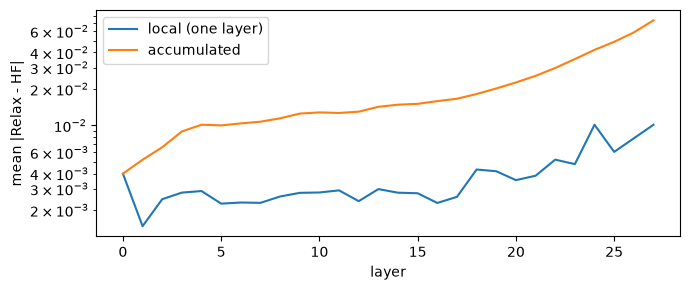

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3))
ax.semilogy([r["local mean_abs"] for r in rows], label="local (one layer)")
ax.semilogy([r["accum mean_abs"] for r in rows], label="accumulated")
ax.set_xlabel("layer"); ax.set_ylabel("mean |Relax - HF|"); ax.legend(); plt.tight_layout(); plt.show()

## The whole model, and what changes for decoding

The real artifact's `forward_hidden` + `get_logits` on the same 64 tokens, against HF's full forward.
The same steps are traced call by call in notebook 06.

There are two separate effects:
- the logits differ slightly;
- Relax applies the 0.9 threshold to **fp32** probabilities, while HF applies it to **bf16**
  probabilities.

The second can flip "unmask now" decisions even when the logits agree.

In [7]:
runner = load_relax("artifacts/fast_dllm_relax_bf16")
emb = runner.vm["embed"](tvm.runtime.tensor(ids[0].int().cpu().numpy(), device=dev), runner.params)
emb = runner.reshape(emb, tvm.runtime.ShapeTuple([1, L, cfg.hidden_size]))
hid = runner.vm["forward_hidden"](emb, bias, runner.params)
lg = runner.vm["get_logits"](hid, runner.params)
with torch.no_grad():
    out = hf(input_ids=ids)
print_table([compare(hid, out.hidden_states, name="final hidden (after norm)"),
             compare(lg, out.logits.float(), name="logits", argmax_axis=-1)])

name                       shape        max_abs  mean_abs  max_rel  equal_frac  argmax_agree
-------------------------  -----------  -------  --------  -------  ----------  ------------
final hidden (after norm)  1x64x1536    2.5      0.04547   0.02041  0.1044                  
logits                     1x64x151936  0.8672   0.05555   0.02392  0.1063      1           


In [8]:
lg_t = torch.from_dlpack(lg)[0]                                    # fp32 logits (Relax)
p_rx = torch.softmax(lg_t, -1).max(-1).values                        # Relax: fp32 softmax
p_hf_bf16 = torch.softmax(out.logits[0], -1).max(-1).values.float()  # HF: bf16 softmax
p_hf_fp32 = torch.softmax(out.logits[0].float(), -1).max(-1).values  # HF logits, fp32 softmax
for name, a, b in [("Relax fp32 vs HF bf16 (as deployed)", p_rx, p_hf_bf16),
                   ("HF fp32 vs HF bf16 (precision alone)", p_hf_fp32, p_hf_bf16),
                   ("Relax fp32 vs HF fp32 (logit gap alone)", p_rx, p_hf_fp32)]:
    flips = int(((a > 0.9) != (b > 0.9)).sum())
    print(f"{name:<42} threshold decisions that differ: {flips} / {L}   max |dconf| {float((a - b).abs().max()):.4f}")

Relax fp32 vs HF bf16 (as deployed)        threshold decisions that differ: 0 / 64   max |dconf| 0.0388
HF fp32 vs HF bf16 (precision alone)       threshold decisions that differ: 0 / 64   max |dconf| 0.0019
Relax fp32 vs HF fp32 (logit gap alone)    threshold decisions that differ: 0 / 64   max |dconf| 0.0376


## Takeaways
- The hand-copied ops (RMSNorm, SiLU, the attention accumulation) are at or near rounding level.
  The rest of the gap comes from **kernel choice** (fused GEMM shapes, explicit attention vs SDPA)
  and the **RoPE formula**.
- The error builds up over the 28 layers. Since decoding is greedy with a threshold, a near-tie can
  still flip a token, and after that the two generations diverge.
- Comparing the threshold on fp32 rather than bf16 probabilities is a separate, deliberate
  difference that can change *how many* tokens a step unmasks without changing *which* tokens.
- Next: **04 · The pipeline, pass by pass**.